# 02. Sparkov: сегменты клиентов 18–25 / 26–59 / 60+
**Задача №14 (Р1).** Пункты кейса 1 и 4.

Что делаем:
1. Возраст на дату операции из `dob`, сегменты 18–25, 26–59, 60+.
2. Признаки нетипичности **для конкретного клиента**: сумма относительно его истории, новая для него категория, всплеск операций за сутки.
3. Два варианта профиля: онлайн (идеал) и «ночной профиль» с задержкой 24 часа — по условию кейса часть данных клиента приходит с задержкой до суток.
4. Показываем, что при **едином пороге** FPR и полнота по сегментам расходятся — это обоснование порогов по сегментам (ноутбук 03).

**Данные:** Kaggle → Add Input → `kartik2112/fraud-detection` (файлы `fraudTrain.csv`, `fraudTest.csv`).

### Общие функции
Сплит по времени, метрики по формулам кейса, цена ошибки, симуляция реакции. Ячейка записывает модуль `antifraud_utils.py` рядом с ноутбуком.

In [1]:
%%writefile antifraud_utils.py
"""
Общие функции для ноутбуков команды (Хакатон ВТБ, задача №6).

Метрики считаются строго по формулам кейса (с. 10):
  точность выявления          = TP / (TP + FP)
  доля ложных сигналов        = FP / (TP + FP)
  FPR (ложные среди законных) = FP / (FP + TN)
  полнота обнаружения         = TP / (TP + FN)
Дополнительно: полнота по сумме (какая доля похищаемых денег остановлена).

Этот же код вставлен первой ячейкой в каждый ноутбук, чтобы ноутбуки
запускались на Kaggle без дополнительных файлов.
"""
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score


# ---------------------------------------------------------------- сплит
def time_split(df, time_col, fracs=(0.6, 0.2, 0.2)):
    """Сплит по времени: train — самые ранние операции, test — самые поздние.
    Случайный сплит запрещён: он подмешивает «будущее» в обучение и завышает метрики."""
    t = df[time_col]
    q1 = t.quantile(fracs[0])
    q2 = t.quantile(fracs[0] + fracs[1])
    train = df[t <= q1]
    valid = df[(t > q1) & (t <= q2)]
    test = df[t > q2]
    return train, valid, test


# ---------------------------------------------------------------- история клиента без утечки
def past_stats(df, group_cols, time_col, value_col, lag=0, window=None):
    """Статистики по ПРОШЛЫМ операциям группы (клиент, клиент+категория, получатель...).

    Для строки с временем t учитываются операции той же группы со временем < t − lag
    (и, если задано window, ≥ t − lag − window). Текущая операция и будущее не учитываются.
    lag=0      — онлайн-признак (поток операций доступен сразу)
    lag=86400  — «ночной профиль»: данные приходят с задержкой до суток (условие кейса)
    Возвращает DataFrame (cnt, sum, mean, std) в порядке индекса df. Векторизовано.
    """
    g = df.groupby(group_cols, sort=False).ngroup().to_numpy().astype(np.int64)
    t = df[time_col].to_numpy().astype(np.int64)
    v = df[value_col].to_numpy().astype(float)
    t = t - t.min()
    big = np.int64(t.max() + lag + (window or 0) + 2)
    key = g * big + t
    order = np.argsort(key, kind="mergesort")
    ks, vs = key[order], v[order]
    cs = np.r_[0.0, np.cumsum(vs)]
    cs2 = np.r_[0.0, np.cumsum(vs ** 2)]
    gs = g[order] * big                                   # начало «окна» группы на оси ключей
    hi = np.searchsorted(ks, ks - lag, side="left")       # строки со временем < t − lag
    lo = np.searchsorted(ks, gs, side="left")             # первая строка группы
    if window is not None:
        lo = np.maximum(lo, np.searchsorted(ks, ks - lag - window, side="left"))
    hi = np.maximum(hi, lo)
    cnt = (hi - lo).astype(float)
    s = cs[hi] - cs[lo]
    s2 = cs2[hi] - cs2[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = np.where(cnt > 0, s / cnt, np.nan)
        var = np.where(cnt > 1, (s2 - s ** 2 / cnt) / (cnt - 1), np.nan)
    out = np.empty((len(df), 4))
    out[order] = np.c_[cnt, s, mean, np.sqrt(np.clip(var, 0, None))]
    return pd.DataFrame(out, index=df.index, columns=["cnt", "sum", "mean", "std"])


# ---------------------------------------------------------------- метрики
def metrics(y, score, threshold, amount=None):
    """Все метрики кейса при заданном пороге. y — 1 мошенничество, 0 законная."""
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)
    pred = score >= threshold
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    res = {
        "n": len(y),
        "n_fraud": int(y.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "false_signal_share": fp / (tp + fp) if tp + fp else np.nan,
        "alert_rate": (tp + fp) / len(y),
        "roc_auc": roc_auc_score(y, score) if 0 < y.sum() < len(y) else np.nan,
        "pr_auc": average_precision_score(y, score) if y.sum() > 0 else np.nan,
        "threshold": threshold,
    }
    if amount is not None:
        amount = np.asarray(amount, dtype=float)
        fraud_amt = amount[y == 1].sum()
        caught = amount[(y == 1) & pred].sum()
        res["fraud_amount"] = fraud_amt
        res["caught_amount"] = caught
        res["missed_amount"] = fraud_amt - caught
        res["amount_recall"] = caught / fraud_amt if fraud_amt else np.nan
    return res


def metrics_by_group(df, group_col, y_col, score_col, threshold, amount_col=None):
    """Метрики по сегментам. threshold — число или dict {сегмент: порог}."""
    rows = []
    for g, part in df.groupby(group_col, observed=True):
        thr = threshold[g] if isinstance(threshold, dict) else threshold
        m = metrics(part[y_col], part[score_col], thr,
                    part[amount_col] if amount_col else None)
        m[group_col] = g
        rows.append(m)
    return pd.DataFrame(rows).set_index(group_col)


def threshold_for_fpr(y, score, target_fpr):
    """Порог, при котором FPR на этих данных не превышает target_fpr."""
    y = np.asarray(y).astype(int)
    legit = np.sort(np.asarray(score, dtype=float)[y == 0])[::-1]
    k = int(np.floor(target_fpr * len(legit)))
    # флагуем только то, что строго выше k-го законного скора (корректно и при одинаковых скорах)
    return float(np.nextafter(legit[min(k, len(legit) - 1)], np.inf))


# ---------------------------------------------------------------- цена ошибки
def cost_curve(y, score, amount, cost_fp, loss_share=1.0):
    """Полная цена ошибок для КАЖДОГО возможного порога (точный перебор).

    Цена пропуска (FN)  = сумма хищения × loss_share
    Цена ложного (FP)   = cost_fp (обработка + ожидаемый отказ от операции)
    Возвращает DataFrame: threshold, TP, FP, missed_amount, cost.
    """
    y = np.asarray(y).astype(int)
    s = np.asarray(score, dtype=float)
    a = np.asarray(amount, dtype=float)
    order = np.argsort(-s, kind="mergesort")
    s, y, a = s[order], y[order], a[order]
    tp = np.cumsum(y)
    fp = np.cumsum(1 - y)
    caught = np.cumsum(a * y)
    total_fraud_amt = (a * y).sum()
    # позиции, где score меняется: порог = s[i], флагуем всё с индексом <= i
    last = np.r_[s[1:] != s[:-1], True]
    idx = np.where(last)[0]
    out = pd.DataFrame({
        "threshold": s[idx],
        "TP": tp[idx], "FP": fp[idx],
        "missed_amount": total_fraud_amt - caught[idx],
    })
    # вариант «не флагуем ничего»
    out = pd.concat([pd.DataFrame({"threshold": [np.inf], "TP": [0], "FP": [0],
                                   "missed_amount": [total_fraud_amt]}), out],
                    ignore_index=True)
    out["cost"] = out["missed_amount"] * loss_share + out["FP"] * cost_fp
    return out


def best_threshold(y, score, amount, cost_fp, loss_share=1.0):
    cc = cost_curve(y, score, amount, cost_fp, loss_share)
    return float(cc.loc[cc["cost"].idxmin(), "threshold"])


def best_threshold_by_group(df, group_col, y_col, score_col, amount_col,
                            cost_fp, loss_share=1.0):
    """Свой порог для каждого сегмента. cost_fp может быть dict по сегментам."""
    thr = {}
    for g, part in df.groupby(group_col, observed=True):
        c = cost_fp[g] if isinstance(cost_fp, dict) else cost_fp
        thr[g] = best_threshold(part[y_col], part[score_col], part[amount_col], c, loss_share)
    return thr


def total_cost(y, score, amount, threshold, cost_fp, loss_share=1.0):
    m = metrics(y, score, threshold, amount)
    return m["missed_amount"] * loss_share + m["FP"] * cost_fp


# ---------------------------------------------------------------- многоуровневая реакция
# Уровень реакции (tier) — dict:
#   name              название
#   stop_fraud        доля мошеннических операций, которые этот уровень останавливает
#   legit_abandon     доля законных клиентов, которые после этой проверки отказываются от операции
#   legit_restricted  доля законных операций, которые на этом уровне приостанавливаются/отменяются
#   op_cost           прямые затраты банка на одну операцию этого уровня (звонок, разбор), руб.
#   kc_inbound        вероятность, что клиент с ошибочным ограничением звонит в КЦ
# Экономика (econ) — dict: loss_share, lost_income_rate (доход банка с суммы операции), kc_cost,
#   churn_cost — ожидаемая потеря будущего дохода от клиента после одного ошибочного ограничения
#   (строка «Снижение использования продукта» в таблице кейса, с. 10).

def _tier_arrays(tiers):
    keys = ["stop_fraud", "legit_abandon", "legit_restricted", "op_cost", "kc_inbound"]
    return {k: np.array([t[k] for t in tiers], dtype=float) for k in keys}


def choose_tier(p, amount, tiers, econ):
    """Для каждой операции — уровень реакции с максимальной ожидаемой выгодой для банка и клиента.

    Выгода = p·сумма·loss_share·stop_fraud                        (сохранённые деньги)
           − (1−p)·p_wrong·[доход·сумма + kc_inbound·kc_cost + churn_cost]  (цена трения)
             где p_wrong = abandon + restricted — вероятность, что законная операция не состоится
           − op_cost                                              (работа банка)
    p — откалиброванная вероятность мошенничества.
    """
    T = _tier_arrays(tiers)
    p = np.asarray(p, dtype=float)[:, None]
    a = np.asarray(amount, dtype=float)[:, None]
    p_wrong = np.clip(T["legit_abandon"] + T["legit_restricted"], 0, 1)[None, :]
    saved = p * a * econ["loss_share"] * T["stop_fraud"][None, :]
    friction = (1 - p) * (p_wrong * econ["lost_income_rate"] * a
                          + p_wrong * T["kc_inbound"][None, :] * econ["kc_cost"]
                          + p_wrong * econ.get("churn_cost", 0.0))
    benefit = saved - friction - T["op_cost"][None, :]
    return benefit.argmax(axis=1)


def simulate_reaction(y, amount, tier_idx, tiers, econ, client_id=None):
    """Ожидаемые последствия выбранных уровней на РАЗМЕЧЕННЫХ данных.

    Ложные сигналы и ошибочно ограниченные операции считаются отдельно (кейс, с. 10):
      false_signals       — законные операции, получившие любую реакцию выше «пропустить»
      wrongly_restricted  — законные операции, которые в итоге отменены или приостановлены
                            (приостановка + ожидаемый отказ клиента после проверки)
    """
    T = _tier_arrays(tiers)
    y = np.asarray(y).astype(int)
    a = np.asarray(amount, dtype=float)
    ti = np.asarray(tier_idx)
    stop = T["stop_fraud"][ti]
    p_wrong = np.clip(T["legit_abandon"] + T["legit_restricted"], 0, 1)[ti]
    fr, lg = y == 1, y == 0
    res = {
        "ops": len(y),
        "fraud_ops": int(fr.sum()),
        "fraud_amount": a[fr].sum(),
        "prevented_amount": (a * stop)[fr].sum(),
        "stolen_amount": (a * (1 - stop))[fr].sum(),
        "fraud_stopped_exp": stop[fr].sum(),          # ожидаемое число остановленных хищений (TP)
        "fraud_flagged": int((ti[fr] > 0).sum()),     # хищения, получившие любую реакцию
        "false_signals": int((ti[lg] > 0).sum()),
        "false_signal_rate": float((ti[lg] > 0).mean()),
        "wrongly_restricted_exp": p_wrong[lg].sum(),
        "wrongly_restricted_rate": float(p_wrong[lg].mean()),
        "kc_inbound_exp": (p_wrong * T["kc_inbound"][ti])[lg].sum(),
        "ops_cost": T["op_cost"][ti].sum(),
        "lost_income": (p_wrong * a)[lg].sum() * econ["lost_income_rate"],
    }
    res["kc_cost"] = res["kc_inbound_exp"] * econ["kc_cost"]
    res["churn_cost"] = res["wrongly_restricted_exp"] * econ.get("churn_cost", 0.0)
    res["amount_recall"] = res["prevented_amount"] / res["fraud_amount"] if res["fraud_amount"] else np.nan
    if client_id is not None:
        cid = np.asarray(client_id)[lg]
        # вероятность, что у клиента за период было хотя бы одно ошибочное ограничение
        log_ok = pd.Series(np.log1p(-np.clip(p_wrong[lg], 0, 0.999999))).groupby(cid).sum()
        res["clients"] = int(len(np.unique(np.asarray(client_id))))
        res["clients_wrongly_restricted_exp"] = float((1 - np.exp(log_ok)).sum())
    return res


def tier_table(y, tier_idx, tiers):
    """Сколько законных и мошеннических операций попало на каждый уровень."""
    y = np.asarray(y).astype(int)
    df = pd.DataFrame({"tier": [tiers[i]["name"] for i in tier_idx], "y": y})
    t = df.groupby("tier")["y"].agg(ops="size", fraud="sum")
    t["legit"] = t["ops"] - t["fraud"]
    return t.reindex([x["name"] for x in tiers]).fillna(0).astype(int)


def fmt_rub(x):
    return f"{x/1e6:,.2f} млн руб.".replace(",", " ")


Writing antifraud_utils.py


In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from antifraud_utils import *
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

# На Kaggle датасеты лежат в /kaggle/input, результаты пишем в /kaggle/working
DATA_DIR = os.environ.get("DATA_DIR", "/kaggle/input")
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working" if os.path.exists("/kaggle/working") else "output")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name, dirs=(DATA_DIR, OUT_DIR)):
    for d in dirs:
        hits = sorted(glob.glob(os.path.join(d, "**", name), recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} не найден. В Kaggle: Add Input → подключите нужный датасет/ноутбук")


In [3]:
import gc
# Читаем только нужные колонки: имена, адреса, профессии и номера транзакций не нужны и съедают память
USECOLS = ["trans_date_trans_time", "cc_num", "category", "amt", "gender", "lat", "long",
           "city_pop", "dob", "merch_lat", "merch_long", "is_fraud"]
DTYPES = {"cc_num": "int64", "category": "category", "amt": "float32", "gender": "category",
          "lat": "float32", "long": "float32", "city_pop": "int32",
          "merch_lat": "float32", "merch_long": "float32", "is_fraud": "int8"}
parts = []
for name in ["fraudTrain.csv", "fraudTest.csv"]:
    part = pd.read_csv(find(name), usecols=USECOLS, dtype=DTYPES)
    part["file"] = "train" if "Train" in name else "test"
    parts.append(part)
df = pd.concat(parts, ignore_index=True)
del parts; gc.collect()
df["file"] = df.file.astype("category")
df["category"] = df.category.astype("category")

# Время берём из trans_date_trans_time: unix_time в Sparkov сдвинут и с датой не совпадает
df["ts"] = pd.to_datetime(df.trans_date_trans_time)
df["t"] = (df.ts - pd.Timestamp("1970-01-01")) // pd.Timedelta("1s")   # секунды при любой версии pandas
df["dob"] = pd.to_datetime(df.dob)
df = df.drop(columns="trans_date_trans_time").sort_values("t", kind="mergesort").reset_index(drop=True)
gc.collect()
print(f"Память под таблицу: {df.memory_usage(deep=True).sum() / 1e9:.2f} ГБ")
print(df.shape, df.ts.min(), "→", df.ts.max(), f"мошенничество {df.is_fraud.mean():.3%}, клиентов {df.cc_num.nunique():,}")

Память под таблицу: 0.11 ГБ
(1852394, 14) 2019-01-01 00:00:18 → 2020-12-31 23:59:34 мошенничество 0.521%, клиентов 999


## 1. Возраст и сегменты

In [4]:
df["age"] = ((df.ts - df.dob).dt.days / 365.25).astype("float32")
print(f"Младше 18 лет: {(df.age < 18).mean():.2%} операций — относим к сегменту 18–25")
SEGMENTS = ["18–25", "26–59", "60+"]
df["segment"] = pd.Categorical(np.select([df.age < 26, df.age < 60], SEGMENTS[:2], SEGMENTS[2]),
                               categories=SEGMENTS, ordered=True)

seg = df.groupby("segment", observed=True).agg(
    clients=("cc_num", "nunique"), ops=("is_fraud", "size"), fraud_ops=("is_fraud", "sum"),
    avg_amt=("amt", "mean"))
seg["fraud_rate"] = seg.fraud_ops / seg.ops
seg["avg_fraud_amt"] = df[df.is_fraud == 1].groupby("segment", observed=True).amt.mean()
seg["share_of_fraud_amt"] = df[df.is_fraud == 1].groupby("segment", observed=True).amt.sum() / df.loc[df.is_fraud == 1, "amt"].sum()
seg

Младше 18 лет: 1.18% операций — относим к сегменту 18–25


,clients,ops,fraud_ops,avg_amt,fraud_rate,avg_fraud_amt,share_of_fraud_amt
segment,,,,,,,
18–25,116,199138,1115,63.4541,0.0056,565.8093,0.1232
26–59,652,1258163,5960,72.3999,0.0047,507.6419,0.5908
60+,291,395093,2576,65.9548,0.0065,568.7074,0.2861


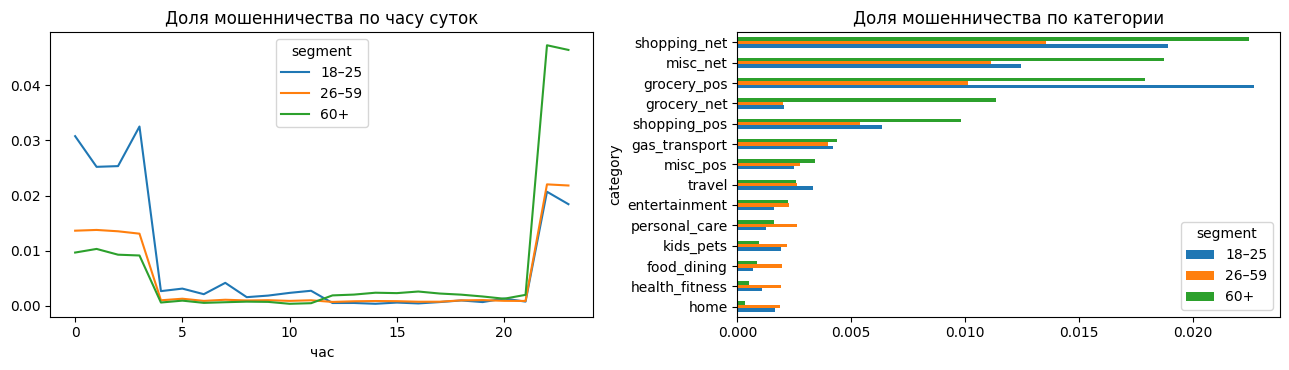

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df.groupby([df.ts.dt.hour, "segment"], observed=True).is_fraud.mean().unstack().plot(ax=ax[0])
ax[0].set_title("Доля мошенничества по часу суток"); ax[0].set_xlabel("час")
df.groupby(["category", "segment"], observed=True).is_fraud.mean().unstack().sort_values("60+").plot.barh(ax=ax[1])
ax[1].set_title("Доля мошенничества по категории")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sparkov_eda.png", dpi=120); plt.show()

## 2. Признаки
**Онлайн** (поток операций банка доступен сразу): сумма, время, категория, всплеск операций клиента за 1 ч и 24 ч, время с прошлой операции.
**Профиль клиента** (средняя сумма, разброс, привычные категории): считаем в двух вариантах — без задержки и с задержкой 24 часа.
Все истории — только по прошлым операциям (`past_stats`), будущее не подмешивается.

In [6]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# --- статичные и онлайн-признаки
df["log_amt"] = np.log1p(df.amt)
df["hour"] = df.ts.dt.hour
df["is_night"] = df.hour.isin([22, 23, 0, 1, 2, 3]).astype(int)
df["dow"] = df.ts.dt.dayofweek
df["category_c"] = df.category
df["is_male"] = (df.gender == "M").astype(int)
df["log_city_pop"] = np.log1p(df.city_pop)
df["dist_km"] = haversine_km(df.lat, df["long"], df.merch_lat, df.merch_long)

w1 = past_stats(df, ["cc_num"], "t", "amt", window=3600)
w24 = past_stats(df, ["cc_num"], "t", "amt", window=86400)
df["cnt_1h"], df["cnt_24h"], df["sum_24h"] = w1.cnt, w24.cnt, w24["sum"]
df["secs_since_prev"] = df.groupby("cc_num").t.diff()

ONLINE = ["amt", "log_amt", "hour", "is_night", "dow", "category_c", "is_male", "age",
          "log_city_pop", "dist_km", "cnt_1h", "cnt_24h", "sum_24h", "secs_since_prev"]

# --- профиль клиента с заданной задержкой
def profile(lag):
    c = past_stats(df, ["cc_num"], "t", "amt", lag=lag)
    k = past_stats(df, ["cc_num", "category"], "t", "amt", lag=lag)
    p = pd.DataFrame(index=df.index)
    p["cli_cnt"] = c.cnt
    p["cli_mean"] = c["mean"]
    p["amt_ratio"] = df.amt / c["mean"]
    p["amt_z"] = (df.amt - c["mean"]) / c["std"].replace(0, np.nan)
    p["cat_cnt"] = k.cnt
    p["cat_new"] = (k.cnt == 0).astype(int)
    p["cat_share"] = k.cnt / c.cnt.replace(0, np.nan)
    p["amt_cat_ratio"] = df.amt / k["mean"]
    return p

PROFILE = ["cli_cnt", "cli_mean", "amt_ratio", "amt_z", "cat_cnt", "cat_new", "cat_share", "amt_cat_ratio"]
prof_online = profile(0).astype("float32")
prof_lag24 = profile(86400).astype("float32")
gc.collect()
pd.concat([prof_lag24.groupby(df.is_fraud).median().T.rename(columns={0: "законные", 1: "мошенничество"})], axis=1)

is_fraud,законные,мошенничество
cli_cnt,"1,108.0000",561.0000
cli_mean,64.9057,63.3334
amt_ratio,0.6647,6.0341
amt_z,-0.1880,3.1861
cat_cnt,83.0000,41.0000
cat_new,0.0000,0.0000
cat_share,0.0806,0.0786
amt_cat_ratio,0.8140,4.9059


## 3. Сплит по времени
`fraudTest` (вторая половина 2020) — тест. Из `fraudTrain` последние 20% по времени — валидация для ранней остановки и подбора порогов.

In [7]:
is_test = df.file.eq("test")
q = df.loc[~is_test, "t"].quantile(0.8)
split = np.where(is_test, "test", np.where(df.t > q, "valid", "train"))
for s in ["train", "valid", "test"]:
    m = split == s
    print(f"{s:5s}: {df.ts[m].min():%Y-%m-%d} – {df.ts[m].max():%Y-%m-%d}, {m.sum():,} операций, мошенничество {df.is_fraud[m].mean():.3%}")

PARAMS = dict(objective="binary", metric="average_precision", learning_rate=0.05, num_leaves=63,
              min_child_samples=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              verbose=-1, seed=42)

def fit(X):
    tr, va = split == "train", split == "valid"
    m = lgb.train(PARAMS, lgb.Dataset(X[tr], df.is_fraud[tr]), 3000,
                  valid_sets=[lgb.Dataset(X[va], df.is_fraud[va])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    return m, m.predict(X)

X_on = pd.concat([df[ONLINE], prof_online], axis=1)
X_lag = pd.concat([df[ONLINE], prof_lag24], axis=1)
X_base = df[["amt", "log_amt", "hour", "is_night", "dow", "category_c", "is_male", "age", "log_city_pop", "dist_km"]]

m_base, s_base = fit(X_base)   # без истории клиента
m_on, s_on = fit(X_on)         # профиль онлайн — верхняя граница
m_lag, s_lag = fit(X_lag)      # профиль с задержкой 24 ч — реалистичный вариант, берём как основной
df["score"] = s_lag
print("итераций:", m_base.best_iteration, m_on.best_iteration, m_lag.best_iteration)

train: 2019-01-01 – 2020-03-06, 1,037,340 операций, мошенничество 0.575%
valid: 2020-03-06 – 2020-06-21, 259,335 операций, мошенничество 0.593%
test : 2020-06-21 – 2020-12-31, 555,719 операций, мошенничество 0.386%
итераций: 157 510 646


## 4. Единый порог для всех: как расходятся сегменты
Порог подбираем на валидации так, чтобы общий FPR был не выше 1%, и смотрим метрики на тесте по сегментам.

In [8]:
TARGET_FPR = 0.01
va, te = df[split == "valid"], df[split == "test"]
COLS = ["dataset", "variant", "segment", "split", "n", "n_fraud", "TP", "FP", "FN",
        "precision", "recall", "FPR", "false_signal_share", "amount_recall", "roc_auc", "pr_auc", "threshold"]

rows = []
for variant, s in [("Без истории клиента", s_base), ("Бейзлайн: профиль онлайн", s_on),
                   ("Бейзлайн: профиль с задержкой 24 ч", s_lag)]:
    s_va, s_te = s[split == "valid"], s[split == "test"]
    thr = threshold_for_fpr(va.is_fraud, s_va, TARGET_FPR)
    for name, part, sc in [("valid", va, s_va), ("test", te, s_te)]:
        m = metrics(part.is_fraud, sc, thr, part.amt); m.update(segment="все", split=name, variant=variant)
        rows.append(m)
    by = metrics_by_group(te.assign(score_=s_te), "segment", "is_fraud", "score_", thr, "amt").reset_index()
    by["split"], by["variant"] = "test", variant
    rows += by.to_dict("records")
res = pd.DataFrame(rows).assign(dataset="Sparkov")[COLS]
res

,dataset,variant,segment,split,n,n_fraud,TP,FP,FN,precision,recall,FPR,false_signal_share,amount_recall,roc_auc,pr_auc,threshold
0,Sparkov,Без истории клиента,все,valid,259335,1538,1492,2577,46,0.3667,0.9701,0.0100,0.6333,0.9957,0.9985,0.9242,0.0128
1,Sparkov,Без истории клиента,все,test,555719,2145,2046,5439,99,0.2733,0.9538,0.0098,0.7267,0.9877,0.9974,0.8806,0.0128
2,Sparkov,Без истории клиента,18–25,test,54029,220,216,710,4,0.2333,0.9818,0.0132,0.7667,0.9978,0.9987,0.8445,0.0128
3,Sparkov,Без истории клиента,26–59,test,378619,1350,1277,3897,73,0.2468,0.9459,0.0103,0.7532,0.9810,0.9972,0.8416,0.0128
4,Sparkov,Без истории клиента,60+,test,123071,575,553,832,22,0.3993,0.9617,0.0068,0.6007,0.9980,0.9972,0.9553,0.0128
5,Sparkov,Бейзлайн: профиль онлайн,все,valid,259335,1538,1531,2577,7,0.3727,0.9954,0.0100,0.6273,0.9989,0.9995,0.9860,0.0000
6,Sparkov,Бейзлайн: профиль онлайн,все,test,555719,2145,2126,4935,19,0.3011,0.9911,0.0089,0.6989,0.9990,0.9994,0.9739,0.0000
7,Sparkov,Бейзлайн: профиль онлайн,18–25,test,54029,220,220,457,0,0.3250,1.0000,0.0085,0.6750,1.0000,1.0000,0.9912,0.0000
8,Sparkov,Бейзлайн: профиль онлайн,26–59,test,378619,1350,1339,3492,11,0.2772,0.9919,0.0093,0.7228,0.9989,0.9996,0.9650,0.0000
9,Sparkov,Бейзлайн: профиль онлайн,60+,test,123071,575,567,986,8,0.3651,0.9861,0.0080,0.6349,0.9988,0.9983,0.9833,0.0000


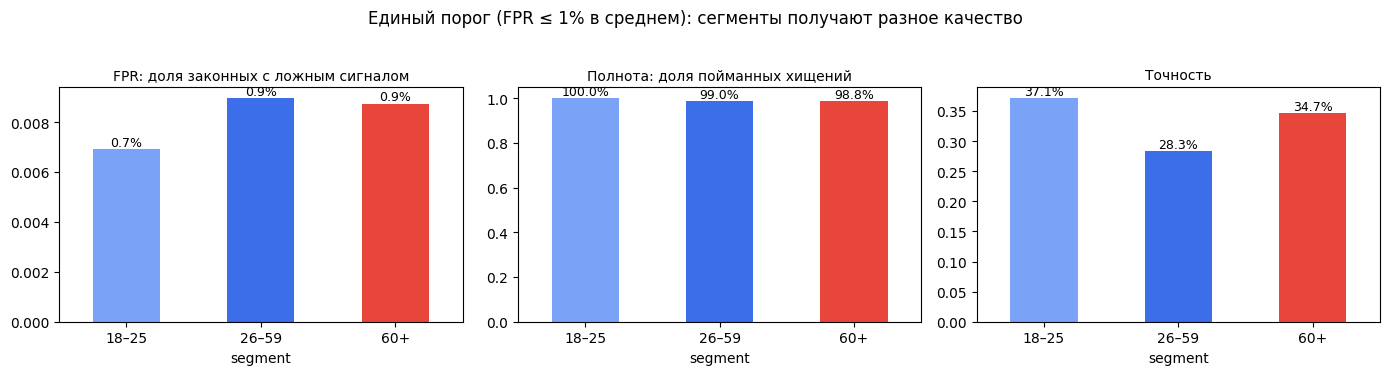

,n,n_fraud,FPR,recall,precision,amount_recall
segment,,,,,,
18–25,54029,220,0.0069,1.0000,0.3710,1.0000
26–59,378619,1350,0.0090,0.9896,0.2835,0.9973
60+,123071,575,0.0087,0.9878,0.3466,0.9990


In [9]:
main = res[(res.variant == "Бейзлайн: профиль с задержкой 24 ч") & (res.split == "test") & (res.segment != "все")].set_index("segment")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, title in zip(ax, ["FPR", "recall", "precision"],
                         ["FPR: доля законных с ложным сигналом", "Полнота: доля пойманных хищений", "Точность"]):
    main[col].plot.bar(ax=a, color=["#7aa2f7", "#3b6ee8", "#e8463b"], rot=0); a.set_title(title, fontsize=10)
    for i, v in enumerate(main[col]):
        a.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
plt.suptitle("Единый порог (FPR ≤ 1% в среднем): сегменты получают разное качество", y=1.03)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sparkov_single_threshold_by_segment.png", dpi=120, bbox_inches="tight"); plt.show()
main[["n", "n_fraud", "FPR", "recall", "precision", "amount_recall"]]

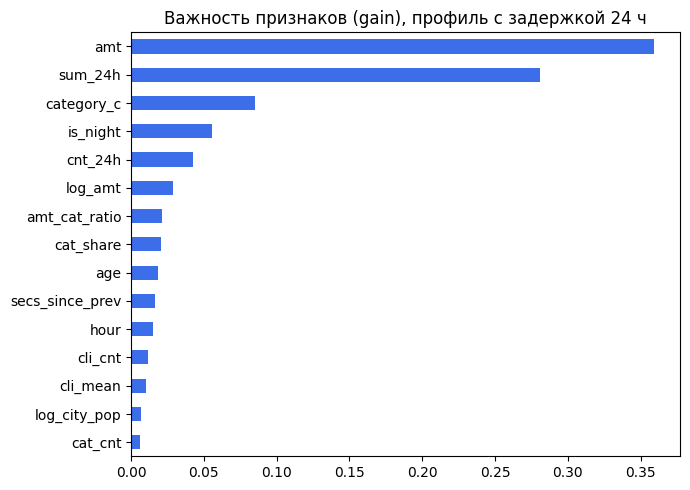

In [10]:
imp = pd.Series(m_lag.feature_importance("gain"), index=X_lag.columns).sort_values()
(imp / imp.sum()).tail(15).plot.barh(figsize=(7, 5), color="#3b6ee8", title="Важность признаков (gain), профиль с задержкой 24 ч")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sparkov_importance.png", dpi=120); plt.show()

## 5. Сохранение
Строки для листа «Метрики моделей» и скоры валидации/теста для ноутбука 03.

In [11]:
res.to_csv(f"{OUT_DIR}/metrics_sparkov_segments.csv", index=False)
out = df.loc[split != "train", ["cc_num", "t", "segment", "category", "amt", "is_fraud", "score"]].copy()
out.insert(0, "split", split[split != "train"])
out.to_csv(f"{OUT_DIR}/sparkov_scores.csv.gz", index=False)
print("Сохранено в", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Сохранено в /kaggle/working : ['__notebook__.ipynb', '__pycache__', 'antifraud_utils.py', 'metrics_sparkov_segments.csv', 'sparkov_eda.png', 'sparkov_importance.png', 'sparkov_scores.csv.gz', 'sparkov_single_threshold_by_segment.png']


## Выводы для слайда
- **Основная модель** (профиль клиента с задержкой 24 ч), тест: полнота **99,0%**, ложных **0,87%**, остановлено 99,8% суммы, PR-AUC 0,975.
- **История клиента** (нетипичность суммы и категории) поднимает PR-AUC с 0,881 до 0,975 и сокращает пропуски с 99 до 21.
- **Задержка профиля на сутки почти ничего не стоит**: PR-AUC 0,974 (онлайн) против 0,975 (с задержкой). Профиль можно считать ночным пакетом, онлайн нужны только сумма и всплески за 1 ч / 24 ч — аргумент для схемы «онлайн-признаки + ночной профиль».
- **Сегменты.** У простой модели единый порог даёт разный FPR: 18–25 — 1,32%, 60+ — 0,68%. У модели с историей клиента разница почти исчезает: 0,69% / 0,90% / 0,87%. Поэтому отдельные пороги по сегментам не нужны (проверено в ноутбуке 03), различия сегментов учитываются в уровнях реакции.
- Оговорка: Sparkov синтетический и «лёгкий»; на слайды выносим относительные эффекты, не абсолютные проценты.